# EDA 与 Day-type analysis
这是可运行的分析工作簿，非报告正文。依据 specs/project_spec.pdf 第 2–5 页。

- 初始 EDA、PCA、聚类选型及拟合：仅 **2010–2013**。
- 2014 为验证期；2015–2026.10 为后续观察期。后续结果不用于修改本工作簿的初始聚类选择。
- 市场日以 interval start date 定义；2026 年只有 1–10 月。
- 不训练预测模型，不实现在线漂移 detector，不删除负电价或价格尖峰。
- 图表与统计结果在 notebook 中显示；仅导出一份 `day_types.csv` 供后续预测误差分析使用。重启 kernel 后需按顺序重新运行。


In [1]:
from pathlib import Path
import sys, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import sklearn
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / 'harness').is_dir():
    ROOT = ROOT / 'comp9417/project/comp9417_project_kit'
assert (ROOT / 'harness/dayahead.py').is_file(), '请从 kit 目录打开 notebook'
sys.path.insert(0, str(ROOT / 'harness'))
import dayahead as da
SEED = 9417
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': .2})

def show_plot():
    plt.tight_layout()
    plt.show()

print('Python', platform.python_version(), 'numpy', np.__version__,
      'pandas', pd.__version__, 'sklearn', sklearn.__version__)

Python 3.11.18 numpy 2.4.6 pandas 3.1.0 sklearn 1.9.1


## 1. 数据完整性与标签
先核对原始顺序和时间完整性，再计算 market day。分类阈值为前一市场日 48 个价格的平均值；第一天没有前一天，标签保留为缺失，不能强行填 0。

前日均价逐组调用 `Series.mean()`，与官方 harness 一致，避免 `groupby.mean()` 在严格大于的临界值上产生舍入差异。例如 2017-05-14 18:30 的价格等于前日均价，应标为 0；不通过四舍五入或人为容差改变官方定义。

In [2]:
raw = pd.read_csv(ROOT / 'data/nem_weather_halfhourly_2010_2026.csv', parse_dates=['timestamp'])
assert raw.timestamp.is_monotonic_increasing
assert not raw.timestamp.duplicated().any()
assert not raw.isna().any().any()
df = raw.set_index('timestamp')
assert df.index.equals(pd.date_range('2010-01-01 00:30', '2026-11-01 00:00', freq='30min'))
df['day'] = da.market_day(df.index)
df['period'] = (df.index - pd.Timedelta('30min')).hour * 2 + (df.index - pd.Timedelta('30min')).minute // 30
assert df.groupby('day').size().eq(48).all()
df['year'] = df.day.dt.year
df['weekday'] = df.day.dt.day_of_week
df['month'] = df.day.dt.month
df['season'] = df.month.map({12:'Summer',1:'Summer',2:'Summer',3:'Autumn',4:'Autumn',5:'Autumn',6:'Winter',7:'Winter',8:'Winter',9:'Spring',10:'Spring',11:'Spring'})
# Match the official Series.mean() reduction exactly, including equality cases.
means = df.groupby('day').nsw_price.agg(lambda prices: prices.mean())
df['previous_mean_price'] = df.day.map(means.shift(1))
df['y_up'] = (df.nsw_price > df.previous_mean_price).astype('Int64')
df.loc[df.previous_mean_price.isna(), 'y_up'] = pd.NA
train = df.loc[df.year.between(2010, 2013)].copy()
for target in ['2010-01-02', '2014-01-01', '2024-02-29', '2026-10-31', '2017-05-14']:
    official = da.targets(df, target)
    np.testing.assert_array_equal(df.loc[official.index, 'y_up'].to_numpy(dtype=int), official.nsw_price_up)
assert df.loc[pd.Timestamp('2017-05-14 18:30'), 'y_up'] == 0
audit = {'rows':len(df), 'market_days':df.day.nunique(), 'first':str(df.index.min()), 'last':str(df.index.max()),
         'training_rows':len(train), 'training_days':train.day.nunique(), 'missing_raw':int(raw.isna().sum().sum())}
print(audit)
display((train[da.MARKET_COLS + da.WEATHER_COLS].describe(percentiles=[.01,.5,.99]).T))

{'rows': 295104, 'market_days': 6148, 'first': '2010-01-01 00:30:00', 'last': '2026-11-01 00:00:00', 'training_rows': 70128, 'training_days': 1461, 'missing_raw': 0}


,count,mean,std,min,1%,50%,99%,max
nsw_demand,70128.0,8442.447227,1338.610483,5074.63,5874.7862,8449.04,11682.9121,14579.86
nsw_price,70128.0,41.689485,147.105939,-264.31,14.9600,31.30,89.9573,12136.17
qld_demand,70128.0,5834.370907,832.319254,4040.80,4373.8924,5896.38,7806.8048,8890.66
qld_price,70128.0,42.955648,134.952778,-1000.00,11.0700,29.87,153.5646,9207.97
vic_demand,70128.0,5683.957649,887.916355,3551.60,4080.2397,5631.91,7799.5595,9858.30
vic_price,70128.0,40.268942,159.092757,-817.03,9.9400,32.05,92.6592,9998.59
syd_temp,70128.0,17.505664,4.576823,3.80,8.1000,17.55,28.5500,39.20
syd_rh,70128.0,71.563234,14.844565,15.00,33.5000,73.00,96.0000,100.00
syd_cloud,70128.0,48.458619,39.175245,0.00,0.0000,46.00,100.0000,100.00
syd_solar,70128.0,191.236938,265.914751,0.00,0.0000,16.50,958.0000,1122.00


## 2. 需求 EDA（仅训练期）
比较星期、季节及每日需求水平。工作日不等于非假日，星期图没有单独控制 public holidays。曲线是均值，不是峰值；带宽为逐日同一时段的 10–90% 分位数，不是置信区间。

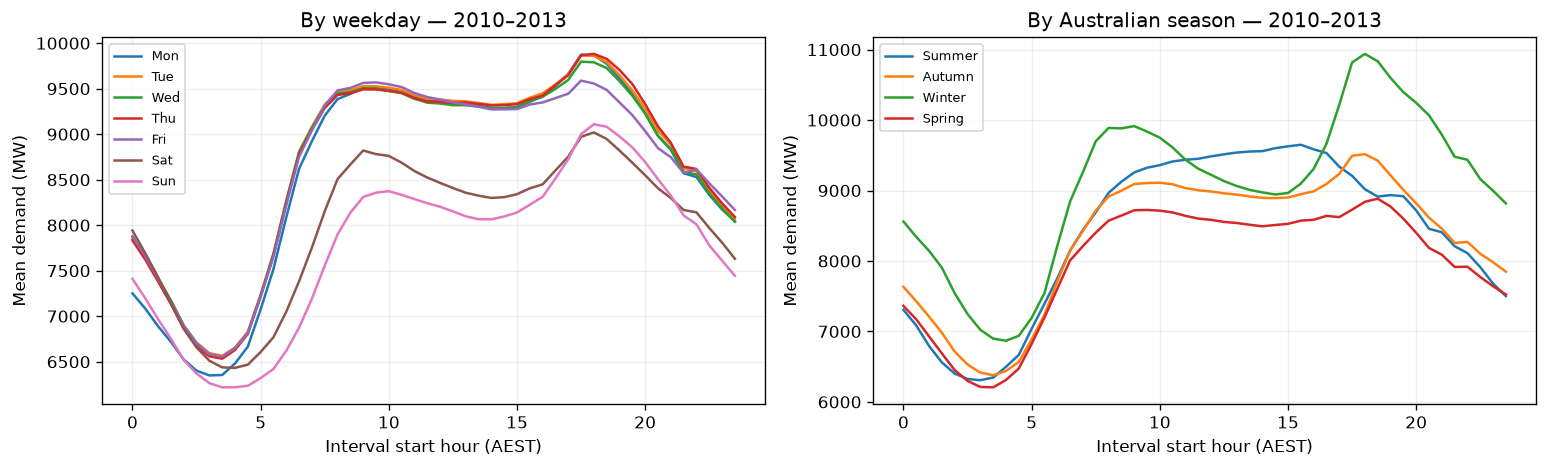

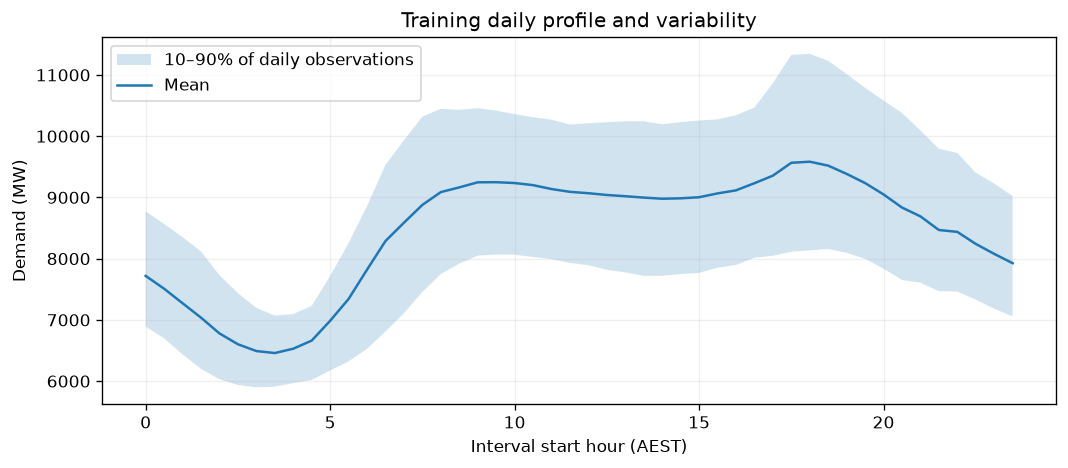

In [3]:
hours = np.arange(48) / 2
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for key, group in train.groupby('weekday'):
    axes[0].plot(hours, group.groupby('period').nsw_demand.mean(), label=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][key])
for key in ['Summer','Autumn','Winter','Spring']:
    axes[1].plot(hours, train.loc[train.season.eq(key)].groupby('period').nsw_demand.mean(), label=key)
for ax, title in zip(axes, ['By weekday', 'By Australian season']):
    ax.set(xlabel='Interval start hour (AEST)', ylabel='Mean demand (MW)', title=title+' — 2010–2013')
    ax.legend(fontsize=8)
show_plot()

p = train.groupby('period').nsw_demand
plt.figure(figsize=(9,4))
plt.fill_between(hours, p.quantile(.1), p.quantile(.9), alpha=.2, label='10–90% of daily observations')
plt.plot(hours, p.mean(), label='Mean')
plt.xlabel('Interval start hour (AEST)'); plt.ylabel('Demand (MW)')
plt.title('Training daily profile and variability'); plt.legend()
show_plot()

## 3. 天气关系与历史 lag
使用分箱均值展示关系；不控制时段、季节等混杂因素，不能作因果解释。相关性也不等于预测增益，增益需要 2014 验证。

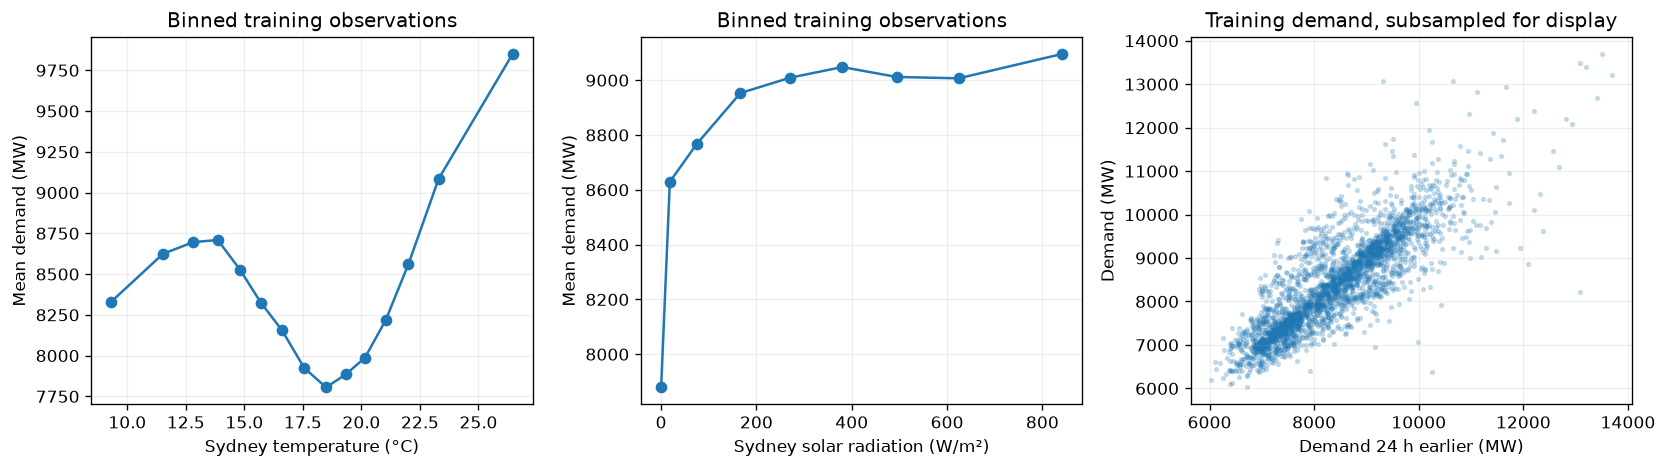

,demand,lag1,lag7
demand,1.000000,0.885560,0.874887
lag1,0.885560,1.000000,0.813296
lag7,0.874887,0.813296,1.000000


In [4]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, col, label in zip(axes[:2], ['syd_temp','syd_solar'], ['Sydney temperature (°C)','Sydney solar radiation (W/m²)']):
    bins = pd.qcut(train[col], q=15, duplicates='drop')
    points = train.groupby(bins, observed=True).agg(x=(col,'mean'), demand=('nsw_demand','mean'))
    ax.plot(points.x, points.demand, 'o-')
    ax.set(xlabel=label, ylabel='Mean demand (MW)', title='Binned training observations')
sample = train.iloc[::24]
axes[2].scatter(sample.nsw_demand.shift(2), sample.nsw_demand, s=5, alpha=.2)
# sample is spaced 12 hours, so shift(2) is one day; compute exact correlations below.
axes[2].set(xlabel='Demand 24 h earlier (MW)', ylabel='Demand (MW)', title='Training demand, subsampled for display')
show_plot()
lag_table = pd.DataFrame({'demand':df.nsw_demand, 'lag1':df.nsw_demand.shift(48), 'lag7':df.nsw_demand.shift(336)})
display((lag_table.loc[train.index].corr()))

## 4. 电价与标签 EDA
保留所有价格。用 symlog 横轴同时展示负数和尖峰；标签 1 表示高于前一天均价，不代表正电价。最后一个小图考察“前一天均价与次日类别比例”的关系，属于标签分析，不可将次日比例当成预测输入。

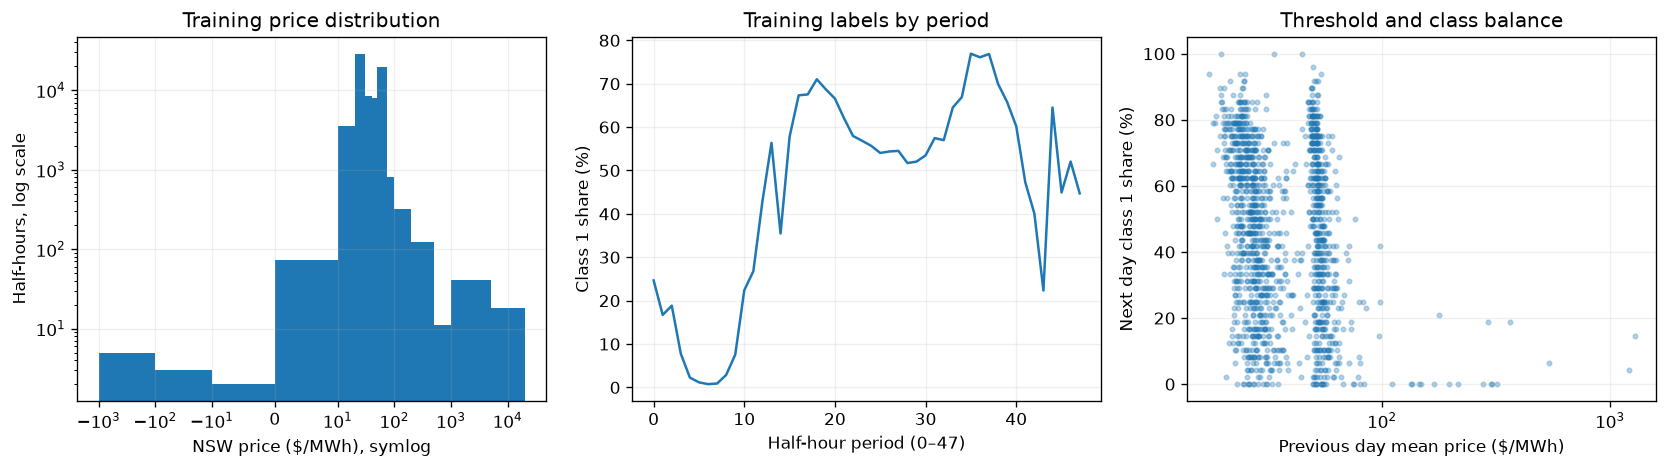

,n,negative_share,class1_pct
year,,,
2010,17520,0.039954,46.17674
2011,17520,0.011416,43.687215
2012,17568,0.005692,46.630237
2013,17520,0.000000,47.385845


In [5]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
axes[0].hist(train.nsw_price, bins=np.r_[-1000,-100,-10,0,10,20,30,40,50,75,100,200,500,1000,5000,20000])
axes[0].set_xscale('symlog', linthresh=10); axes[0].set_yscale('log')
axes[0].set(xlabel='NSW price ($/MWh), symlog', ylabel='Half-hours, log scale', title='Training price distribution')
train.groupby('period').y_up.mean().astype(float).mul(100).plot(ax=axes[1])
axes[1].set(xlabel='Half-hour period (0–47)', ylabel='Class 1 share (%)', title='Training labels by period')
daily_labels = df.groupby('day').agg(previous_mean_price=('previous_mean_price','first'), positive_share=('y_up','mean'))
a = daily_labels.loc['2010':'2013'].dropna()
axes[2].scatter(a.previous_mean_price, a.positive_share.astype(float)*100, s=7, alpha=.3)
axes[2].set_xscale('symlog', linthresh=10)
axes[2].set(xlabel='Previous day mean price ($/MWh)', ylabel='Next day class 1 share (%)', title='Threshold and class balance')
show_plot()
class_summary = train.groupby('year').agg(n=('nsw_price','size'), negative_share=('nsw_price',lambda x:100*x.lt(0).mean()), class1_pct=('y_up',lambda x:100*x.mean()))
display((class_summary))

## 5. 每日 48 维曲线与表示选择
主分析选择**每日需求除以每日均值**：聚焦形状，避免仅按用电规模分组。代价是忽略总水平变化，因此另外保留每日 MW 均值，并用 raw MW 方案作敏感性比较。

PCA 保留至少 90% 训练方差；不额外逐时段标准化，以免改变各时段在曲线距离中的含义。候选 k=2…6，选择训练期 silhouette 最大者，同时输出 inertia、最小簇比例及不同种子稳定性，供人工判断分组是否有解释性。所有选择均不使用后续数据。

/Users/tuzi/unsw/26t3/comp9417/project/.venv/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/tuzi/unsw/26t3/comp9417/project/.venv/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/tuzi/unsw/26t3/comp9417/project/.venv/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^


,representation,k,n_pc,variance_retained,silhouette,inertia,smallest_cluster_pct
0,shape,2,3,0.9201,0.4297,8.873430e+01,45.5852
1,shape,3,3,0.9201,0.3630,7.189590e+01,14.7844
2,shape,4,3,0.9201,0.3169,5.759280e+01,11.4305
3,shape,5,3,0.9201,0.3680,4.457100e+01,10.7461
4,shape,6,3,0.9201,0.3605,3.895960e+01,8.8296
5,raw_mw,2,2,0.9270,0.4301,2.683279e+10,47.0226
6,raw_mw,3,2,0.9270,0.4206,1.711624e+10,22.2450
7,raw_mw,4,2,0.9270,0.4315,1.322785e+10,15.3320
8,raw_mw,5,2,0.9270,0.4196,1.047665e+10,11.1567
9,raw_mw,6,2,0.9270,0.4311,8.125721e+09,4.8597


,representation,seed,ARI_vs_selected
0,shape,0,0.994528
1,shape,1,1.000000
2,shape,2,0.994528
3,shape,3,1.000000
4,shape,4,0.994528
5,raw_mw,0,0.997823
6,raw_mw,1,0.992304
7,raw_mw,2,0.992304
8,raw_mw,3,0.998109
9,raw_mw,4,0.965653


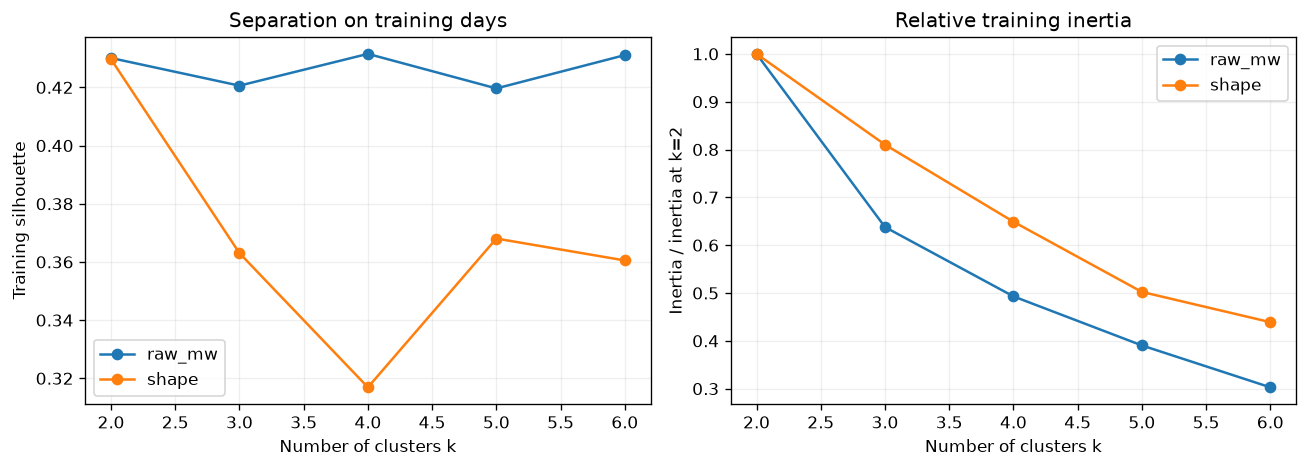

In [6]:
profiles = df.pivot(index='day', columns='period', values='nsw_demand').sort_index()
assert profiles.shape[1] == 48 and not profiles.isna().any().any()
training_days = profiles.index.year <= 2013
representations = {'shape': profiles.div(profiles.mean(axis=1), axis=0), 'raw_mw': profiles}
fitted, diagnostics, seed_checks = {}, [], []
with threadpool_limits(limits=2):
    for name, representation in representations.items():
        fit_x = representation.loc[training_days].to_numpy()
        pca = PCA(n_components=.90, svd_solver='full').fit(fit_x)
        z = pca.transform(fit_x)
        candidates = []
        for k in range(2,7):
            km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(z)
            sil = silhouette_score(z, km.labels_)
            row = {'representation':name, 'k':k, 'n_pc':pca.n_components_,
                   'variance_retained':pca.explained_variance_ratio_.sum(),
                   'silhouette':sil, 'inertia':km.inertia_,
                   'smallest_cluster_pct':100*np.bincount(km.labels_,minlength=k).min()/len(z)}
            diagnostics.append(row); candidates.append((sil,km))
        km = max(candidates, key=lambda pair:pair[0])[1]
        for seed in [0,1,2,3,4]:
            other = KMeans(n_clusters=km.n_clusters, n_init=20, random_state=seed).fit(z)
            seed_checks.append({'representation':name,'seed':seed,'ARI_vs_selected':adjusted_rand_score(km.labels_,other.labels_)})
        fitted[name] = {'pca':pca,'kmeans':km,'fit_last_day':str(profiles.index[training_days].max()),'normalisation':name}
diag = (pd.DataFrame(diagnostics))
display(diag.round(4)); display((pd.DataFrame(seed_checks)))
fig, axes = plt.subplots(1,2,figsize=(11,4))
for name, group in diag.groupby('representation'):
    axes[0].plot(group.k,group.silhouette,'o-',label=name)
    axes[1].plot(group.k,group.inertia/group.inertia.iloc[0],'o-',label=name)
axes[0].set(xlabel='Number of clusters k',ylabel='Training silhouette',title='Separation on training days')
axes[1].set(xlabel='Number of clusters k',ylabel='Inertia / inertia at k=2',title='Relative training inertia')
for ax in axes: ax.legend()
show_plot()

### PCA 方差保留诊断
下图仅使用训练期，显示前几个主成分保留的累计方差；红线为预先设定的 90%。

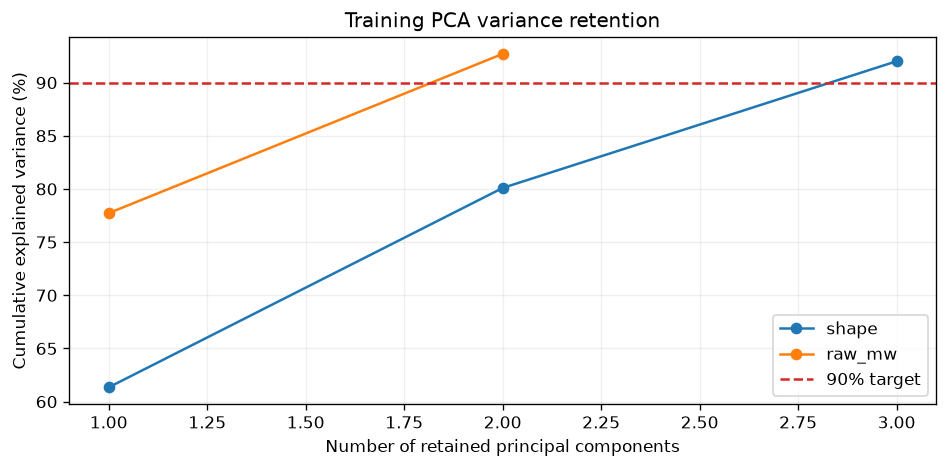

In [7]:
fig, ax = plt.subplots(figsize=(8,4))
for name, model in fitted.items():
    ratios = model['pca'].explained_variance_ratio_
    ax.plot(np.arange(1,len(ratios)+1), np.cumsum(ratios)*100, 'o-', label=name)
ax.axhline(90,color='tab:red',ls='--',label='90% target')
ax.set(xlabel='Number of retained principal components',ylabel='Cumulative explained variance (%)',title='Training PCA variance retention')
ax.legend(); show_plot()

## 6. 固定聚类、典型曲线与解释表
聚类编号没有天然含义，不是已知的工作日/周末标签。输出工作日比例、季节构成、午间/晚间比值等辅助解释；典型曲线和解释统计仅基于训练日。

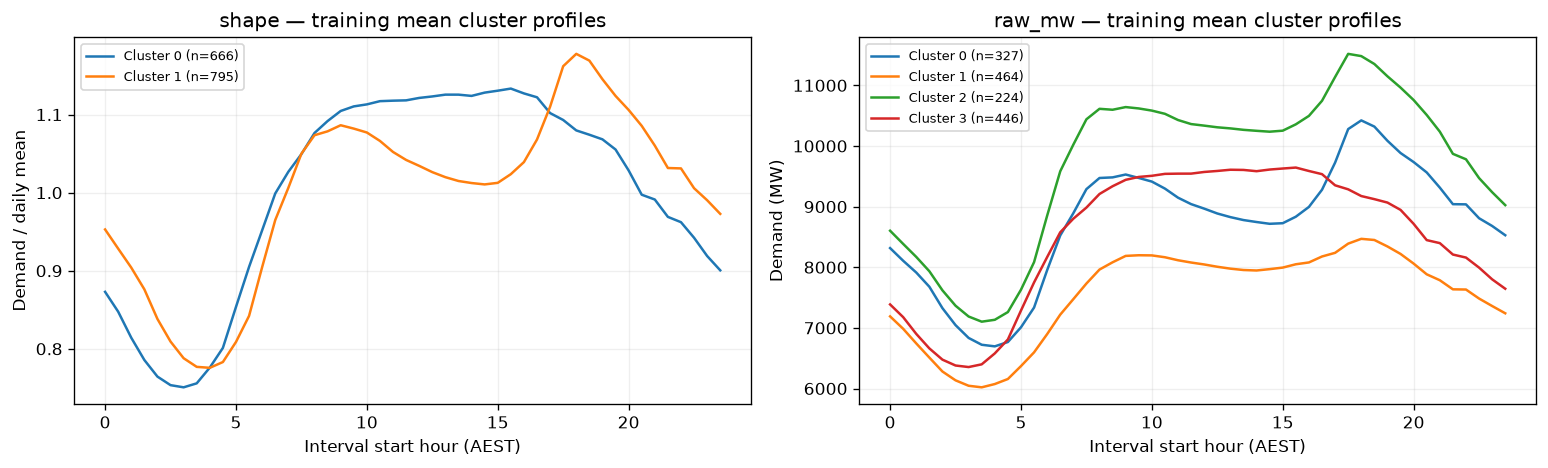

,n_training_days,weekend_pct,mean_daily_demand_mw,mean_profile_peak_start_hour,midday_evening_ratio,Summer_pct,Autumn_pct,Winter_pct,Spring_pct
cluster,,,,,,,,,
0,666,16.967,8407.866,15.5,1.053,48.198,23.874,0.000,27.928
1,795,38.365,8471.417,18.0,0.899,5.031,26.289,46.289,22.390


shape_cluster,0,1
year,,
2010,49.041096,50.958904
2011,45.205479,54.794521
2012,43.989071,56.010929
2013,44.109589,55.890411
2014,41.643836,58.356164
2015,38.904110,61.095890
2016,37.158470,62.841530
2017,33.972603,66.027397
2018,30.958904,69.041096


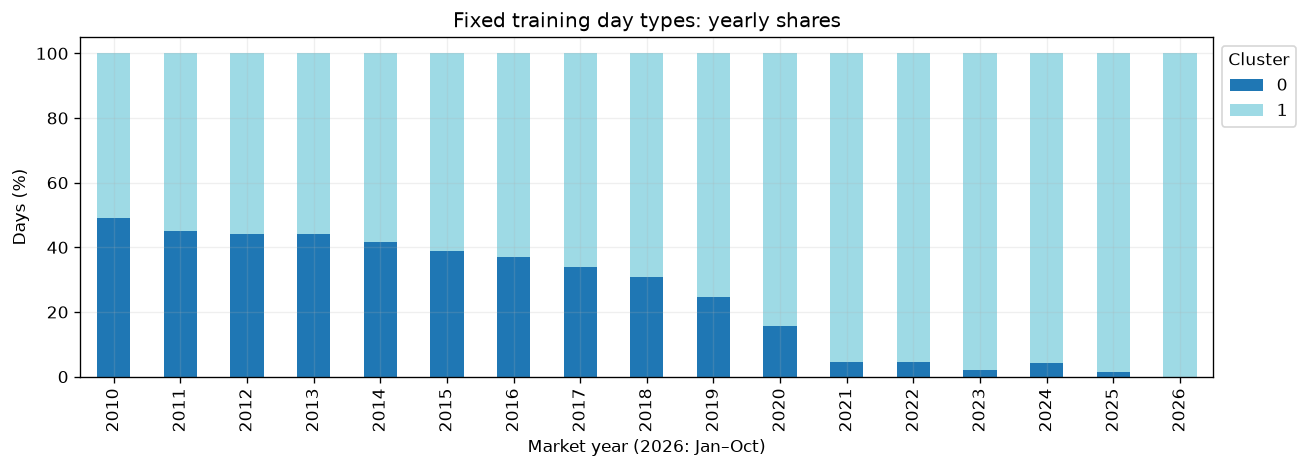

shape_cluster,0,1
year,,
2010,42.105263,57.894737
2011,37.500000,62.500000
2012,36.393443,63.606557
2013,37.828947,62.171053
2014,33.552632,66.447368
2015,32.894737,67.105263
2016,29.508197,70.491803
2017,28.289474,71.710526
2018,26.973684,73.026316


In [8]:
assignments = pd.DataFrame(index=profiles.index)
assignments['daily_mean_mw'] = profiles.mean(axis=1)
fig, axes = plt.subplots(1,2,figsize=(13,4))
interpretations = []
for ax, name in zip(axes, representations):
    model = fitted[name]; pca, km = model['pca'], model['kmeans']
    z_all = pca.transform(representations[name].to_numpy())
    labels = km.predict(z_all)
    assignments[name+'_cluster'] = labels
    for c in range(km.n_clusters):
        mask = training_days & (labels == c)
        typical = representations[name].loc[mask].mean()
        ax.plot(hours, typical, label=f'Cluster {c} (n={mask.sum()})')
        if name == 'shape':
            days = profiles.index[mask]
            mw = profiles.loc[mask]
            norm = representations[name].loc[mask].mean()
            row = {'cluster':c,'n_training_days':int(mask.sum()),'weekend_pct':100*np.mean(days.day_of_week>=5),
                   'mean_daily_demand_mw':mw.mean(axis=1).mean(),
                   'mean_profile_peak_start_hour':float(norm.idxmax()/2),
                   'midday_evening_ratio':norm.loc[23:26].mean()/norm.loc[37:39].mean()}
            seasons = pd.Series(days.month).map({12:'Summer',1:'Summer',2:'Summer',3:'Autumn',4:'Autumn',5:'Autumn',6:'Winter',7:'Winter',8:'Winter',9:'Spring',10:'Spring',11:'Spring'})
            row.update({s+'_pct':100*seasons.eq(s).mean() for s in ['Summer','Autumn','Winter','Spring']})
            interpretations.append(row)
    ax.set(xlabel='Interval start hour (AEST)',ylabel='Demand / daily mean' if name=='shape' else 'Demand (MW)',title=name+' — training mean cluster profiles')
    ax.legend(fontsize=8)
show_plot()
display((pd.DataFrame(interpretations).set_index('cluster')).round(3))
assignments['year'] = assignments.index.year
shares = pd.crosstab(assignments.year, assignments.shape_cluster, normalize='index')*100
display(shares)
shares.plot.bar(stacked=True,figsize=(11,4),colormap='tab20')
plt.xlabel('Market year (2026: Jan–Oct)'); plt.ylabel('Days (%)'); plt.title('Fixed training day types: yearly shares')
plt.legend(title='Cluster',bbox_to_anchor=(1,1)); show_plot()
# Same-month comparison avoids confusing incomplete 2026 coverage with annual change.
matched = assignments.loc[assignments.index.month<=10]
display(pd.crosstab(matched.year,matched.shape_cluster,normalize='index')*100)

## 7. 距离与 PCA 重建残差：统一月度口径
计算每日到最近聚类中心的 PCA 空间距离，以及被 PCA 丢弃维度上的重建 RMSE；再按市场月计算每日统计量的均值。

**两张图均使用月均值：蓝线为各月均值，红线为 2010–2013 共 48 个训练月均值的第 99 百分位数。** 这是描述性参照，不是校准好的在线 detector。48 个月的高分位数不稳定，且没有控制季节性、跨月依赖和重复检验。

年度表中的超限比例另有明确的每日口径：每日值与训练每日值的 99% 分位数比较。日阈值与月阈值分开命名，不能混用。

K-means 会把每一天强制分到最近的一类，即使它远离所有训练簇；后期集中到某类不能解释为形状与早期完全相同。真实 day D 曲线仅在 D 结束后可知，不能用当天真实类型预测当天。

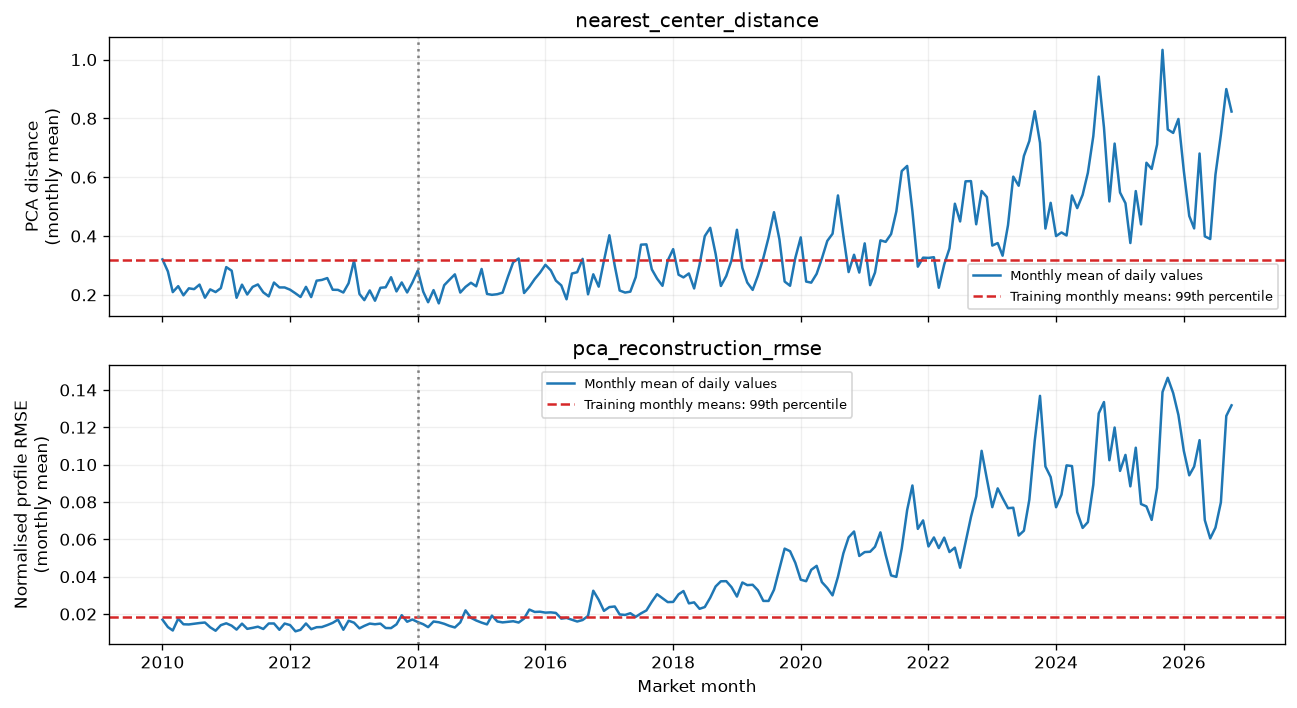

,daily_mean_mw,mean_distance,daily_distance_above_train_daily_q99_pct,daily_reconstruction_above_train_daily_q99_pct
year,,,,
2010,8807.187,0.229,1.644,0.822
2011,8728.238,0.230,1.096,0.274
2012,8253.310,0.223,0.000,0.820
2013,7981.571,0.226,1.370,2.192
2014,7917.807,0.226,0.274,2.192
2015,7979.763,0.247,1.918,6.849
2016,7977.994,0.262,1.913,16.393
2017,8053.852,0.286,4.110,24.932
2018,7999.930,0.305,3.562,53.425


,daily_q99,monthly_mean_q99
nearest_center_distance,0.569583,0.318535
pca_reconstruction_rmse,0.027630,0.018500


,daily_mean_mw,shape_cluster,raw_mw_cluster,year,nearest_center_distance,pca_reconstruction_rmse,nearest_center_distance_above_train_daily_q99,pca_reconstruction_rmse_above_train_daily_q99
day,,,,,,,,
2010-01-01,7791.703958,1,1,2010,0.352749,0.022704,False,False
2010-01-02,8011.402500,0,3,2010,0.298773,0.013551,False,False
2010-01-03,7392.263542,0,1,2010,0.319315,0.012475,False,False
2010-01-04,8256.694583,0,3,2010,0.068742,0.018801,False,False
2010-01-05,8832.867083,0,3,2010,0.284752,0.013329,False,False
...,...,...,...,...,...,...,...,...
2026-10-27,6655.314375,1,1,2026,0.865849,0.128215,True,True
2026-10-28,6409.187708,1,1,2026,1.090698,0.163250,True,True
2026-10-29,6279.538958,1,1,2026,1.267597,0.193684,True,True


In [9]:
pca, km = fitted['shape']['pca'], fitted['shape']['kmeans']
x = representations['shape'].to_numpy()
z = pca.transform(x)
metrics = ['nearest_center_distance', 'pca_reconstruction_rmse']
assignments['nearest_center_distance'] = km.transform(z).min(axis=1)
assignments['pca_reconstruction_rmse'] = np.sqrt(np.mean((x-pca.inverse_transform(z))**2, axis=1))

# Daily thresholds are used ONLY for daily exceedance rates in the yearly table.
daily_thresholds = {col: float(assignments.loc[training_days, col].quantile(.99)) for col in metrics}
for col in metrics:
    assignments[col+'_above_train_daily_q99'] = assignments[col] > daily_thresholds[col]

# The graph uses monthly means on BOTH sides of the comparison.
monthly_metrics = assignments[metrics].resample('MS').mean()
training_months = monthly_metrics.index.year <= 2013
assert training_months.sum() == 48
monthly_thresholds = {col: float(monthly_metrics.loc[training_months, col].quantile(.99)) for col in metrics}
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, col in zip(axes, metrics):
    ax.plot(monthly_metrics.index, monthly_metrics[col], label='Monthly mean of daily values')
    ax.axhline(monthly_thresholds[col], color='tab:red', ls='--', label='Training monthly means: 99th percentile')
    ax.axvline(pd.Timestamp('2014-01-01'), color='grey', ls=':')
    ylabel = 'PCA distance\n(monthly mean)' if col == 'nearest_center_distance' else 'Normalised profile RMSE\n(monthly mean)'
    ax.set(ylabel=ylabel, title=col)
    ax.legend(fontsize=8)
axes[-1].set_xlabel('Market month')
show_plot()
year_stats = assignments.groupby('year').agg(
    daily_mean_mw=('daily_mean_mw', 'mean'),
    mean_distance=('nearest_center_distance', 'mean'),
    daily_distance_above_train_daily_q99_pct=('nearest_center_distance_above_train_daily_q99', lambda x: 100*x.mean()),
    daily_reconstruction_above_train_daily_q99_pct=('pca_reconstruction_rmse_above_train_daily_q99', lambda x: 100*x.mean()))
display(year_stats.round(3))
display(pd.DataFrame({'daily_q99': daily_thresholds, 'monthly_mean_q99': monthly_thresholds}))
display(assignments)


### 导出日类型交接表
仅导出 `day_types.csv`。每行是一个 market day，`day_type` 对应主方案的 `shape_cluster`（不是价格标签）。中心距离在归一化曲线的 PCA 空间计算，PCA 与中心只用 2010–2013 拟合。

用于事后分析时，按 `market_day` 与需求预测误差连接。用于在线检测时，day D 的这行只能在 D 结束后读取。

In [10]:
day_types = assignments[['shape_cluster', 'nearest_center_distance', 'pca_reconstruction_rmse', 'daily_mean_mw']].rename(columns={'shape_cluster': 'day_type'}).copy()
day_types.index.name = 'market_day'
assert len(day_types) == 6148 and day_types.index.is_unique
assert not day_types.isna().any().any()
export_path = ROOT / 'day_types.csv'
day_types.to_csv(export_path, index=True, date_format='%Y-%m-%d', float_format='%.12g')
print(f'Exported {len(day_types)} market days to {export_path.name}')
display(day_types.head())

Exported 6148 market days to day_types.csv


,day_type,nearest_center_distance,pca_reconstruction_rmse,daily_mean_mw
market_day,,,,
2010-01-01,1,0.352749,0.022704,7791.703958
2010-01-02,0,0.298773,0.013551,8011.402500
2010-01-03,0,0.319315,0.012475,7392.263542
2010-01-04,0,0.068742,0.018801,8256.694583
2010-01-05,0,0.284752,0.013329,8832.867083


### 后续历史描述：不用于初始选型
年度负电价比例与分类标签比例是不同统计量。2026 只有 1–10 月，下面同时输出各年份 1–10 月的统计以供公平比较。需求曲线变化不能单独归因于任何市场事件。

,negative_price_pct,class1_pct,mean_demand_mw,midday_mw,evening_mw
year,,,,,
2010,0.047971,43.853135,8906.996665,9612.914679,9949.198333
2011,0.013706,43.153783,8854.856821,9455.411266,9922.131075
2012,0.006831,47.185792,8359.024996,8834.664590,9394.318721
2013,0.000000,46.498081,8051.783442,8537.671785,9000.798531
2014,0.000000,48.834978,7980.067199,8379.468898,8980.579221
2015,0.006853,45.22341,8033.147451,8348.903339,9136.185789
2016,0.000000,39.494536,8008.928760,8314.553205,9105.518033
2017,0.000000,42.591831,8106.508137,8287.575000,9255.368454
2018,0.000000,40.090461,8072.863189,8094.801752,9295.429353


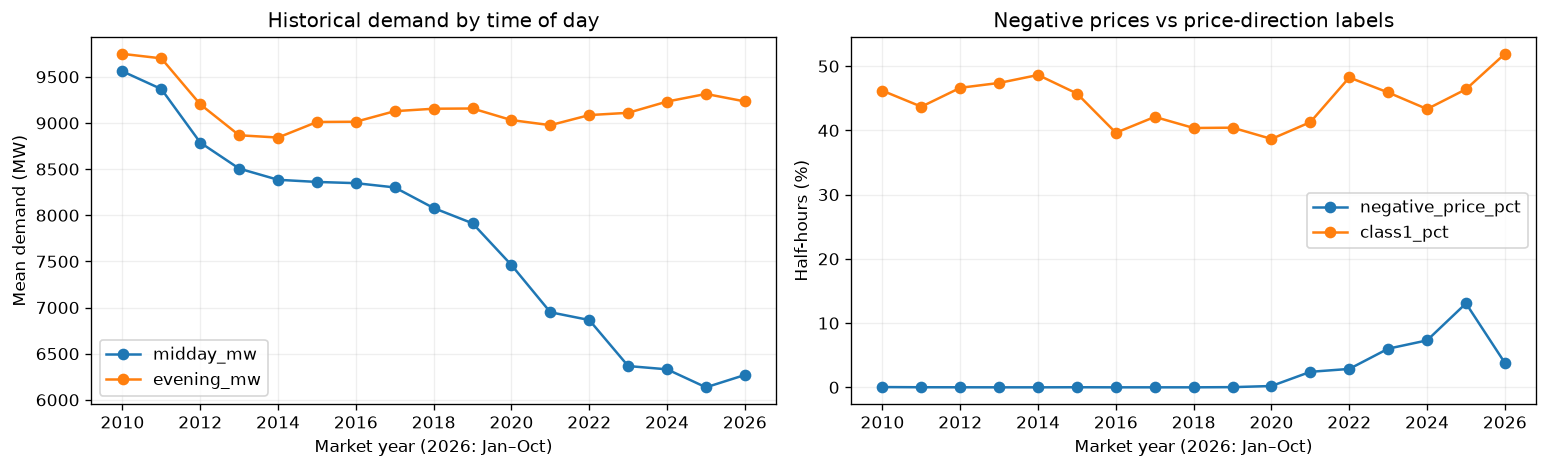

,negative_price_pct,class1_pct,mean_demand_mw,midday_mw,evening_mw
year,,,,,
2010,0.040,46.177,8807.187,9559.469,9748.561
2011,0.011,43.687,8728.238,9367.176,9699.998
2012,0.006,46.63,8253.310,8787.452,9201.802
2013,0.000,47.386,7981.571,8505.656,8866.664
2014,0.000,48.624,7917.807,8384.287,8841.929
2015,0.011,45.736,7979.763,8361.008,9010.533
2016,0.000,39.629,7977.994,8347.799,9013.357
2017,0.000,42.1,8053.852,8301.575,9127.806
2018,0.000,40.371,7999.930,8078.193,9154.235


In [11]:
def historical_summary(data):
    result = data.groupby('year').agg(negative_price_pct=('nsw_price',lambda x:100*x.lt(0).mean()),class1_pct=('y_up',lambda x:100*x.mean()),mean_demand_mw=('nsw_demand','mean'))
    result['midday_mw'] = data.loc[data.period.isin([23,24,25,26])].groupby('year').nsw_demand.mean()
    result['evening_mw'] = data.loc[data.period.isin([37,38,39])].groupby('year').nsw_demand.mean()
    return result
history_summary = (historical_summary(df))
display(historical_summary(df.loc[df.month<=10]))
fig, axes = plt.subplots(1,2,figsize=(13,4))
history_summary[['midday_mw','evening_mw']].plot(ax=axes[0],marker='o')
history_summary[['negative_price_pct','class1_pct']].plot(ax=axes[1],marker='o')
axes[0].set(xlabel='Market year (2026: Jan–Oct)',ylabel='Mean demand (MW)',title='Historical demand by time of day')
axes[1].set(xlabel='Market year (2026: Jan–Oct)',ylabel='Half-hours (%)',title='Negative prices vs price-direction labels')
show_plot()
display(history_summary.round(3))

## 8. 后续接入预测误差（暂不执行）
尚无正式模型历史预测，因此不能声称已完成“日类型变化与模型误差关联”。下方函数在有预测后使用。

输入 prediction_table：每行一个时段、一个模型，列为 timestamp、model、y_demand、pred_demand。使用官方相同的 market day 将真实曲线类型和预测误差关联；类型仅用于事后分组评价，不进入目标日预测。

后续应比较：各类型 MAPE/MAE、各年各类型误差，以及年度类型占比变化是否与整体误差变化同时出现。共时变化不证明因果。

In [12]:
def errors_by_day_type(prediction_table):
    p = prediction_table.copy()
    p['timestamp'] = pd.to_datetime(p['timestamp'])
    assert not p.duplicated(['timestamp','model']).any()
    assert np.isfinite(p[['y_demand','pred_demand']].to_numpy()).all()
    assert p.y_demand.gt(0).all()
    p['day'] = da.market_day(pd.DatetimeIndex(p.timestamp))
    assert p.groupby(['model','day']).size().eq(48).all(), '需要完整每日预测'
    p = p.merge(assignments[['shape_cluster']],left_on='day',right_index=True,how='left',validate='many_to_one')
    assert p.shape_cluster.notna().all()
    p['year'] = p.day.dt.year
    p['ape'] = 100*(p.y_demand-p.pred_demand).abs()/p.y_demand
    p['ae'] = (p.y_demand-p.pred_demand).abs()
    return p.groupby(['model','year','shape_cluster']).agg(n_halfhours=('ape','size'),MAPE=('ape','mean'),MAE=('ae','mean'))

## 阅读结果时的问题
- 星期和季节的需求形状有什么差别？这些观察支持哪些候选特征？
- 价格尖峰如何影响前一天均价和次日标签比例？
- 原始 MW 与归一化方案为何产生不同分组？主方案忽略了哪些信息？
- 选择的 k 是否不仅分数高，还具有解释性？最小簇、种子稳定性如何？
- 固定训练类型能否覆盖后期曲线？最近中心距离与 PCA 残差是否一致？
- 2026 仅 1–10 月，年度比较是否也检查相同月份？
- 分布变化不等于概念漂移。预测误差关联及在线 detector 评价留待正式历史模拟。

图中的分析标签不替代报告图注；请自行根据结果撰写报告和解释。